In [35]:
import subprocess
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import emlearn

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))

from common import contract, data, metrics, paths, plots, verify

import rf

RAIZ = paths.ROOT               # os notebooks moram em utils/
PROCESSADO = paths.SPLITS

LIB = paths.LIB_RF
SRC = paths.LIB_RF_SRC

SCRATCH = paths.SCRATCH

SEMENTE = contract.SEED
ALVO = contract.TARGET
FEATURES = contract.RF_FEATURES

N_ARVORES, MIN_FOLHA = rf.N_TREES, rf.MIN_LEAF

PCA_MIN, PCA_MAX = data.physical_target_limits()

np.random.seed(SEMENTE)

print("emlearn :", emlearn.__version__)
print("features:", ", ".join(FEATURES))
print("splits  : train (2021..2024H1) | calibration (2024H2) | test (2025)")
print("g++ host:", subprocess.run([verify.GXX, "--version"], capture_output=True,
                                 text=True).stdout.splitlines()[0])
print("xtensa  :", "ok" if verify.XTENSA_GXX.exists() else "AUSENTE")
print("entrega :", LIB.relative_to(RAIZ))

emlearn : 0.23.2
features: temperatura_ambiente, ghit, jacques
splits  : train (2021..2024H1) | calibration (2024H2) | test (2025)
g++ host: g++ (Ubuntu 11.4.0-1ubuntu1~22.04.3) 11.4.0
xtensa  : AUSENTE
entrega : lib/knob-senses-rf


In [36]:
treino = data.load_split("train")
calibracao = data.load_split("calibration")
teste = data.load_split("test")

# Sanidade: o csv precisa estar em GRANDEZA FISICA. Se alguem voltar a normalizar no
# prep, estes limites quebram AQUI - e nao em campo, com o firmware normalizando duas
# vezes e a previsao colapsando num valor fixo. Foi o bug real, e custou uma sessao
# inteira de depuracao.
for nome, d in (("train", treino), ("calibration", calibracao), ("test", teste)):
    data.check_physical_scale(nome, d)

print("OK: os tres csv estao em grandeza fisica (brutos)")
print()
for nome, d in (("train", treino), ("calibration", calibracao), ("test", teste)):
    print(f"  {nome:12} {len(d):6} linhas | "
          f"{d.datetime.min().date()} .. {d.datetime.max().date()}")
print()
print(f"{'feature':22} {'min':>9} {'max':>9} {'media treino':>14} {'desvio treino':>14}")
for c in FEATURES:
    print(f"{c:22} {treino[c].min():9.2f} {treino[c].max():9.2f} "
          f"{treino[c].mean():14.4f} {treino[c].std(ddof=0):14.4f}")

OK: os tres csv estao em grandeza fisica (brutos)

  train         78881 linhas | 2021-01-04 .. 2024-06-30
  calibration   11335 linhas | 2024-07-01 .. 2024-12-31
  test          22619 linhas | 2025-01-01 .. 2025-12-31

feature                      min       max   media treino  desvio treino
temperatura_ambiente       14.30     39.93        27.3780         4.0567
ghit                        6.46   1365.02       496.1474       311.9048
jacques                    16.07     70.72        40.4524        11.5598


In [37]:
# Media e desvio SO do treino (2021..2024H1). Calibracao e teste entram depois,
# com as mesmas constantes: normalizacao que espia o futuro maquia a metrica.
MEDIA, DESVIO = data.fit_normalization(treino)

print("constantes de normalizacao (calculadas so no treino):")
print(f"  {'feature':22} {'media':>14} {'desvio':>14}")
for c in FEATURES:
    print(f"  {c:22} {MEDIA[c]:14.6f} {DESVIO[c]:14.6f}")

X_tre = data.z_score(treino, MEDIA, DESVIO).to_numpy(np.float32)
y_tre = treino[ALVO].to_numpy(np.float32)
X_cal = data.z_score(calibracao, MEDIA, DESVIO).to_numpy(np.float32)
y_cal = calibracao[ALVO].to_numpy(np.float32)
X_tes = data.z_score(teste, MEDIA, DESVIO).to_numpy(np.float32)
y_tes = teste[ALVO].to_numpy(np.float32)

# O C recebe BRUTO - e' o bruto do teste que vai para o conferidor, na ordem do csv.
BRUTO_TES = teste[list(FEATURES)].to_numpy(np.float32)

print()
for nome, d in (("treino", treino), ("calibracao", calibracao), ("teste", teste)):
    print(f"  {nome:10} {len(d):6} linhas | PCA {d[ALVO].min():.2f}..{d[ALVO].max():.2f} kW "
          f"| media {d[ALVO].mean():.3f}")

constantes de normalizacao (calculadas so no treino):
  feature                         media         desvio
  temperatura_ambiente        27.377961       4.056654
  ghit                       496.147413     311.904821
  jacques                     40.452367      11.559832

  treino      78881 linhas | PCA 0.01..2.00 kW | media 0.922
  calibracao  11335 linhas | PCA 0.01..1.99 kW | media 0.960
  teste       22619 linhas | PCA 0.01..2.00 kW | media 0.897


In [38]:
from common.metrics import evaluate

resultados = []


In [39]:
from sklearn.dummy import DummyRegressor

media = DummyRegressor(strategy="mean").fit(X_tre, y_tre)
resultados.append(evaluate("media do treino", y_tes, media.predict(X_tes).ravel()))

media do treino      MAE 0.4571 kW | RMSE 0.5279 kW | R2 -0.0023 | vies +0.0254 kW


In [40]:
print(f"{'config':>18} {'nos':>8} {'prof':>5} {'KB (est.)':>10} {'MAE':>8} {'R2':>8} {'s':>5}")
print("-" * 72)

# A varredura avalia na CALIBRACAO (2024H2), nunca no teste. Escolher o tamanho
# pelo teste transformaria a metrica final em treino disfarcado.
varredura = rf.sweep(X_tre, y_tre, X_cal, y_cal)
for r_ in varredura.itertuples():
    print(f"{f'{r_.arvores}arv folha={r_.folha}':>18} {r_.nos:8} {r_.prof:5} {r_.kb:10.1f} "
          f"{r_.mae:8.4f} {r_.r2:8.4f} {r_.s:5.1f}")

top2 = varredura.nlargest(2, "r2")
melhor = top2.loc[top2.s.idxmin()]
print(f"melhor na calibracao (entre os 2 maiores R2, menor tempo): "
      f"{melhor.arvores:.0f} arvores, folha={melhor.folha:.0f} "
      f"(R2={melhor.r2:.4f}, MAE={melhor.mae:.4f}, s={melhor.s:.1f}) "
      f"com {melhor.kb:.0f} KB estimados")

            config      nos  prof  KB (est.)      MAE       R2     s
------------------------------------------------------------------------
    300arv folha=2 13044216    59   178339.5   0.1653   0.8289   1.8
    100arv folha=2  4348138    56    59447.4   0.1656   0.8284   0.7
     50arv folha=5   806638    45    11028.4   0.1635   0.8320   0.4
    50arv folha=20   194128    31     2654.2   0.1614   0.8367   0.3
    30arv folha=50    46142    21      630.9   0.1608   0.8381   0.2
   20arv folha=100    15310    14      209.4   0.1606   0.8386   0.2
   12arv folha=200     4532    11       62.0   0.1607   0.8383   0.1
    6arv folha=400     1126     8       15.4   0.1607   0.8382   0.1
melhor na calibracao (entre os 2 maiores R2, menor tempo): 12 arvores, folha=200 (R2=0.8383, MAE=0.1607, s=0.1) com 62 KB estimados


In [41]:
from sklearn.ensemble import RandomForestRegressor
t0 = time.perf_counter()

rf_modelo = RandomForestRegressor(
  n_jobs=-1, 
  n_estimators=int(melhor.arvores), 
  min_samples_leaf=int(melhor.folha),
  random_state=contract.SEED,
).fit(X_tre, y_tre)

print(f"treino: {time.perf_counter() - t0:.1f} s")

# Calibracao do vies: offset = media(real - previsto) na janela de calibracao
# (2024H2). O modelo foi treinado ate' 2024H1 e 2024H2 ja' mostra a queda de
# eficiencia; medir no teste seria usar o futuro para corrigir o futuro.
pred_cal = rf_modelo.predict(X_cal)
OFFSET_CALIBRACAO = float(np.mean(y_cal - pred_cal))

# A previsao entregue e' sempre a calibrada.
pred_rf = rf_modelo.predict(X_tes) + OFFSET_CALIBRACAO

resultados.append(evaluate("random forest", y_tes, pred_rf))

print(f"\noffset de calibracao (2024H2): {OFFSET_CALIBRACAO:+.4f} kW")

n_nos = rf.count_nodes(rf_modelo)
print(f"\n{n_nos} nos em {rf_modelo.n_estimators} arvores "
      f"({n_nos // rf_modelo.n_estimators} por arvore, profundidade maxima "
      f"{rf.tree_depth(rf_modelo)})")

treino: 0.1 s
random forest        MAE 0.1137 kW | RMSE 0.1574 kW | R2 0.9109 | vies +0.0055 kW

offset de calibracao (2024H2): -0.0990 kW

4532 nos em 12 arvores (377 por arvore, profundidade maxima 11)


In [42]:
# Salva o modelo treinado em dist/ ANTES de gerar a lib C. O .joblib guarda o
# estimador e as constantes necessarias para reproduzir a previsao em Python.
import joblib

paths.DIST.mkdir(parents=True, exist_ok=True)
caminho_modelo = paths.DIST / "random_forest.joblib"
joblib.dump({
    "modelo": rf_modelo,
    "features": list(FEATURES),
    "media": MEDIA.to_dict(),
    "desvio": DESVIO.to_dict(),
    "offset_calibracao_kw": float(OFFSET_CALIBRACAO),
    "pca_min_kw": float(PCA_MIN),
    "pca_max_kw": float(PCA_MAX),
    "metricas": resultados[1],
}, caminho_modelo)
print(f"modelo salvo: {caminho_modelo.relative_to(RAIZ)} "
      f"({caminho_modelo.stat().st_size / 1024:.1f} KB)")

AttributeError: module 'common.paths' has no attribute 'DIST'

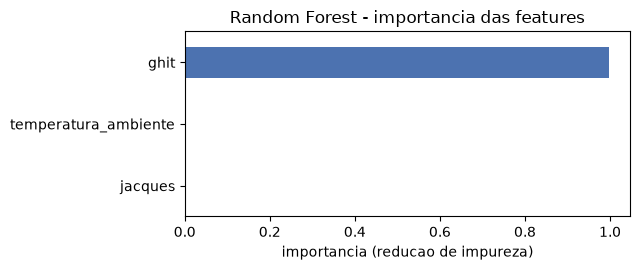

jacques                 0.0010
temperatura_ambiente    0.0019
ghit                    0.9971


In [ ]:
importancia = pd.Series(rf_modelo.feature_importances_, index=FEATURES).sort_values()

plots.plot_importancia(importancia, titulo="Random Forest - importancia das features",
                       figsize=(6.5, 2.8))

print(importancia.round(4).to_string())


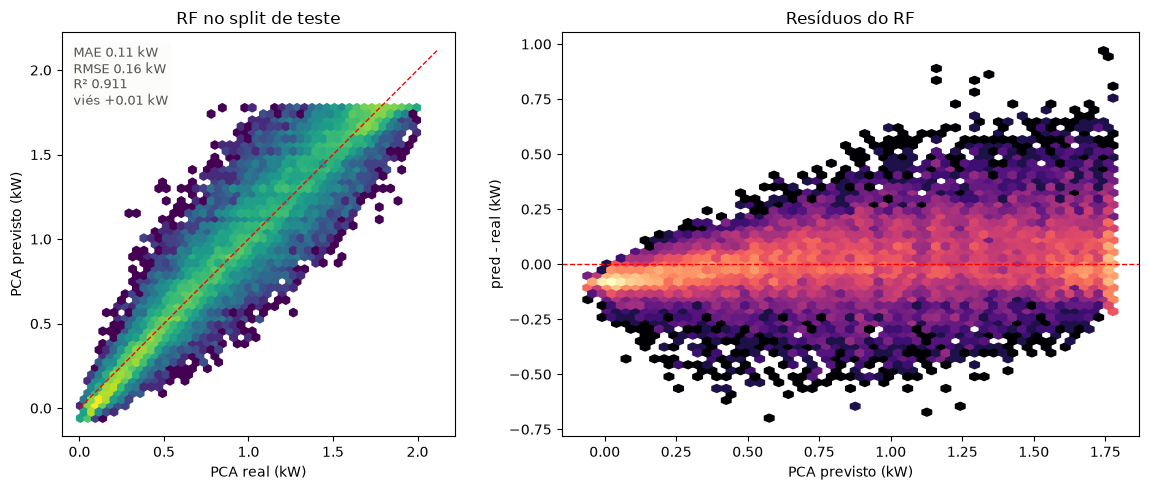

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5), ncols=2)


plots.hexbin_real_vs_pred(ax[0], y_tes, pred_rf, "RF no split de teste")
plots.hexbin_residuo(ax[1], y_tes, pred_rf, "Resíduos do RF")
ax[1].set_ylabel("pred - real (kW)")

texto = chr(10).join([
    f"MAE {resultados[1]['MAE (kW)']:.2f} kW",
    f"RMSE {resultados[1]['RMSE (kW)']:.2f} kW",
    f"R² {resultados[1]['R2']:.3f}",
    f"viés {resultados[1]['vies (kW)']:+.2f} kW",
])
ax[0].text(0.03, 0.97, texto, transform=ax[0].transAxes, va="top",
              color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()

plt.tight_layout()
plt.show()


In [ ]:
escritos = rf.generate_c_lib(rf_modelo, MEDIA, DESVIO,
                     resultados[1]["MAE (kW)"], resultados[1]["R2"],
                     offset=OFFSET_CALIBRACAO)
for caminho in sorted(escritos):
    print(f"  {caminho.relative_to(RAIZ)!s:44} {escritos[caminho]:,} bytes")
print(f"\noffset embutido no C: {OFFSET_CALIBRACAO:+.6f} kW (calibracao 2024H2)")
print("OK: nenhum marcador sobrou nos arquivos gerados")

  lib/knob-senses-rf/README.md                 2,171 bytes
  lib/knob-senses-rf/library.json              543 bytes
  lib/knob-senses-rf/normalizacao.json         935 bytes
  lib/knob-senses-rf/src/knob_senses_rf.cpp    1,193 bytes
  lib/knob-senses-rf/src/knob_senses_rf.h      2,403 bytes

offset embutido no C: -0.099050 kW (calibracao 2024H2)
OK: nenhum marcador sobrou nos arquivos gerados


### O header público

Vale ver o contrato inteiro — é o que quem for usar a lib lê primeiro.

In [ ]:
print((SRC / "knob_senses_rf.h").read_text(encoding="utf-8"))

/*
 * knob-senses - Random Forest de regressao de PCA (potencia CA do inversor, kW).
 *
 * GERADO POR utils/treino_random_forest.ipynb. NAO EDITE A MAO: a proxima execucao
 * do notebook sobrescreve este arquivo.
 *
 * Como usar:
 *
 *     #include <knob_senses_rf.h>
 *
 *     const float bruto[KNOB_RF_N_FEATURES] = { 26.1f, 480.0f, 38.7f };
 *     const float kw = pca_prever(bruto);
 *
 * ORDEM DAS GRANDEZAS BRUTAS:
 *   bruto[0] = temperatura_ambiente
 *   bruto[1] = ghit
 *   bruto[2] = jacques
 *
 * O modelo foi treinado em z-scores e a normalizacao vive DENTRO desta lib (ver
 * knob_senses_rf.cpp): passe a grandeza fisica como ela veio do sensor. Nao normalize
 * antes de chamar pca_prever() - se o dado chegar em z-score, a conta acontece duas
 * vezes, tudo cai a ~7 desvios-padrao da media, e a previsao COLAPSA num valor fixo.
 *
 * Custo: a floresta e' emitida como codigo (emlearn method='inline'), entao nao
 * ocupa RAM; o flash depende do tamanho da floresta - meca no objeto.


In [ ]:
conferidor = verify.write_checker()
exe = verify.compile_host(conferidor)
print("g++: compilou o conferidor junto com o knob_senses_rf.cpp da lib")
print(f"     {exe.relative_to(RAIZ)}  {exe.stat().st_size / 1024:.1f} KB")


g++: compilou o conferidor junto com o knob_senses_rf.cpp da lib
     data/modelo_rf/verifica.exe  96.2 KB


In [ ]:
# Empurra o BRUTO do teste (nao o z-score) pelo executavel.
do_c = verify.predict(exe, BRUTO_TES)
# veredito = verify.compare(do_c, pred_rf, y_tes)

# print(f"linhas conferidas: {veredito['linhas']}")
# print(f"  diferenca mediana            : {veredito['mediana']:.2e} kW   (ruido de float32)")
# print(f"  diferenca media              : {veredito['media']:.2e} kW")
# print(f"  maior diferenca              : {veredito['maior']:.2e} kW")
# print(f"  linhas que trocaram de folha : {veredito['trocas']}")

print()
resultados.append(evaluate("lib compilada", y_tes, do_c))
print("\nOK: a biblioteca reproduz a floresta treinada, com normalizacao, "
      "offset de calibracao e clip")


lib compilada        MAE 0.1133 kW | RMSE 0.1573 kW | R2 0.9110 | vies +0.0059 kW

OK: a biblioteca reproduz a floresta treinada, com normalizacao, offset de calibracao e clip


In [ ]:
print(f"{'modelo':>20} {'MAE':>9} {'RMSE':>9} {'R2':>9} {'MAE c/ clip':>12} {'vies':>9}")
print("-" * 72)
for r_ in resultados:
    print(f"{r_['modelo']:>20} {r_['MAE (kW)']:9.4f} {r_['RMSE (kW)']:9.4f} "
          f"{r_['R2']:9.4f} {r_['MAE com clip (kW)']:12.4f} {r_['vies (kW)']:+9.4f}")

              modelo       MAE      RMSE        R2  MAE c/ clip      vies
------------------------------------------------------------------------
     media do treino    0.4571    0.5279   -0.0023       0.4571   +0.0254
       random forest    0.1137    0.1574    0.9109       0.1133   +0.0055
       lib compilada    0.1133    0.1573    0.9110       0.1133   +0.0059


In [ ]:
# Le o csv exatamente como o model_teste.ipynb le - verbatim, sem tocar nos valores.
amostra = data.read_csv(PROCESSADO / "test.csv")
bruto_rede = amostra[list(FEATURES)].to_numpy(np.float64)

pela_rede = verify.predict(exe, bruto_rede)

erro = np.abs(pela_rede - amostra[ALVO].to_numpy())
amplitude = float(pela_rede.max() - pela_rede.min())

print(f"o caminho inteiro, nas {len(amostra)} linhas de test.csv:")
print(f"  MAE        : {erro.mean():.4f} kW")
print(f"  amplitude  : {amplitude:.4f} kW")
print(f"  primeira   : real {amostra[ALVO].iloc[0]:.4f}  previsto {pela_rede[0]:.4f}")

assert amplitude > 0.1, (
    f"amplitude {amplitude:.5f} kW: a previsao ficou praticamente constante. "
    "Quase sempre e' normalizacao aplicada duas vezes - confira se data/splits/*.csv "
    "nao voltou a sair em z-score.")

print("\nOK: o caminho csv -> rede -> lib devolve previsao util")

o caminho inteiro, nas 22619 linhas de test.csv:
  MAE        : 0.1133 kW
  amplitude  : 1.7770 kW
  primeira   : real 0.0850  previsto 0.0000

OK: o caminho csv -> rede -> lib devolve previsao util


In [ ]:
if not verify.XTENSA_GXX.exists():
    print("xtensa-g++ ausente: medicao de flash/RAM pulada.")
    print("Rode esta celula no ambiente com o toolchain do PlatformIO instalado.")
else:
    medida = verify.measure_xtensa()
    for nome, tamanho in medida["secoes"].items():
        print(f"  {nome:16} {tamanho:7} bytes")

    flash, ram = medida["flash"], medida["ram"]
    print(f"\n  FLASH  {flash:7} bytes  ({flash / 1024:.1f} KB)")
    print(f"  RAM    {ram:7} bytes")

    if ram:
        print(f"\n  ATENCAO: {ram} bytes de RAM. Esperado era zero - o emlearn emite as")
        print("  arvores como codigo, nao como tabela. Confira o que foi para .data/.bss.")
    else:
        print("\n  RAM zero: a floresta e' toda constante e vive no flash.")

xtensa-g++ ausente: medicao de flash/RAM pulada.
Rode esta celula no ambiente com o toolchain do PlatformIO instalado.
